# Notebook 4 — From Correlation to Regression and Machine Learning

Turning relationships into predictions, and using correlation to choose features.

**What you will learn**
1. How **linear regression** builds on correlation to make predictions
2. How correlation helps with **feature selection** for machine-learning models

## Setup
Run this cell first (and again after restarting the kernel). It imports the libraries we need and loads
`cafe_daily.csv`, which must sit in the same folder as this notebook.

- **pandas / numpy** – tables and numerical work
- **matplotlib / seaborn** – plotting
- **scipy.stats** – correlation and regression helpers

`cafe.head()` shows the first five rows so you can check the data loaded correctly.
See `data_dictionary.md` for what every column means.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid")

cafe = pd.read_csv("cafe_daily.csv", parse_dates=["date"])
cafe.head()

,date,day_of_week,is_weekend,temperature_c,iced_drink_sales,hot_drink_sales,cold_brew_sales,salad_sales,foot_traffic,barista_shoe_size,social_followers,promo_active,discount_pct,daily_revenue,daily_profit,pastry_demand
0,2024-01-01,Monday,0,2.0,30,168,11,8,229,41.5,499,1,15,817.78,850.41,70
1,2024-01-02,Tuesday,0,-0.2,25,191,7,14,216,43.0,503,0,35,881.36,560.69,57
2,2024-01-03,Wednesday,0,2.6,30,188,1,18,259,39.0,512,0,20,939.55,840.85,76
3,2024-01-04,Thursday,0,2.9,36,176,12,16,209,45.0,519,0,25,1031.60,780.45,60
4,2024-01-05,Friday,0,-1.8,13,176,2,0,218,42.5,520,1,15,795.42,857.18,65


## Part 1 — Correlation and Regression

Correlation *describes* how strongly two variables are linearly related. **Simple linear regression** *models*
the relationship as a line, so we can predict $y$ from $x$:

$$\hat{y} = \beta_0 + \beta_1 x$$

- $\beta_0$ — **intercept**: predicted $y$ when $x = 0$
- $\beta_1$ — **slope**: change in predicted $y$ for each 1-unit increase in $x$

The line is chosen by **ordinary least squares (OLS)**, which minimises the sum of squared errors
$\sum_i (y_i - \hat{y}_i)^2$. The solution links directly to correlation:

$$\beta_1 = r\,\frac{s_y}{s_x} = \frac{\operatorname{cov}(x,y)}{s_x^2}, \qquad \beta_0 = \bar{y} - \beta_1\,\bar{x}$$

So the slope has the same sign as $r$, and for simple regression $R^2 = r^2$.

Below we predict `pastry_demand` (y) from `temperature_c` (x) with scikit-learn's `LinearRegression`.

pastry_demand ≈ 77.9 + 0.58 × temperature
predicted demand at 20°C: 89


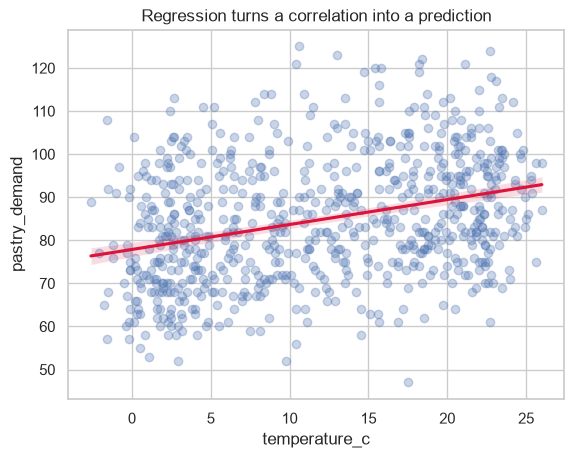

In [2]:
from sklearn.linear_model import LinearRegression
X = cafe[['temperature_c']]; y = cafe['pastry_demand']
lin = LinearRegression().fit(X, y)
print(f'pastry_demand ≈ {lin.intercept_:.1f} + {lin.coef_[0]:.2f} × temperature')
print('predicted demand at 20°C:', round(lin.predict(pd.DataFrame({'temperature_c': [20]}))[0]))
sns.regplot(data=cafe, x='temperature_c', y='pastry_demand',
            scatter_kws={'alpha':.3}, line_kws={'color':'crimson'})
plt.title('Regression turns a correlation into a prediction'); plt.show()

**Reading the result**
- The fitted line is roughly $\widehat{\text{pastry demand}} \approx 77.9 + 0.58 \times \text{temperature}$.
- Slope ≈ 0.58: each extra °C is linked to about 0.6 more pastries per day.
- Prediction at 20 °C: $77.9 + 0.58 \times 20 \approx 89.5$, i.e. about 89 pastries.
- Here $r \approx 0.32$, so $R^2 \approx 0.10$: temperature explains only ~10 % of the variation. The line is useful
  but far from complete — other factors (e.g. foot traffic, weekends) matter more.

> Regression predicts; it does not prove causation (Notebook 3 still applies).

## Part 2 — Correlation and Machine Learning

In machine learning, **features** are the input variables and the **target** is what we predict.
Correlation helps with **feature selection** in three ways:

1. **Find strong predictors** — features with a large $|r|$ with the target
2. **Spot redundant (collinear) features** — features strongly correlated with *each other* carry the same
   information; keeping both adds little and can make models harder to interpret
3. **Drop useless features** — $r \approx 0$ with the target (but remember $r$ only detects *linear* links)

Our target is `daily_revenue`. Let's rank the candidate features by their correlation with it.

In [3]:
# Which features relate to the target (daily_revenue)?
feats = ['temperature_c','iced_drink_sales','hot_drink_sales','cold_brew_sales',
         'salad_sales','foot_traffic','barista_shoe_size','pastry_demand']
cafe[feats + ['daily_revenue']].corr()['daily_revenue'].sort_values(ascending=False)

daily_revenue        1.000000
foot_traffic         0.724132
iced_drink_sales     0.677944
temperature_c        0.632754
cold_brew_sales      0.624821
salad_sales          0.623644
pastry_demand        0.477654
barista_shoe_size    0.002924
hot_drink_sales     -0.510343
Name: daily_revenue, dtype: float64

`foot_traffic` (≈ 0.72) and `iced_drink_sales` (≈ 0.68) are the strongest positive predictors, `hot_drink_sales`
(≈ −0.51) is a strong *negative* predictor (still useful — the sign just tells the direction), and
`barista_shoe_size` (≈ 0.00) carries no information.

Now a redundancy check between two features:

In [4]:
# Redundancy check: temperature and iced_drink_sales carry almost the same signal
print('r(temperature, iced_drink_sales) =',
      round(cafe['temperature_c'].corr(cafe['iced_drink_sales']), 3),
      '  <- collinear, keep one')

r(temperature, iced_drink_sales) = 0.902   <- collinear, keep one


$r \approx 0.90$ between temperature and iced-drink sales: they carry almost the same signal (**collinearity**).
In a simple, interpretable model we would usually keep just one of them.

### Building a model

We train a **random forest** (many decision trees averaged together, which can capture non-linear patterns):

- `train_test_split` keeps 25 % of the days aside as a **test set** the model never sees during training.
- The score is $R^2$ on the test set:

$$R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}$$

  $R^2 = 1$ is a perfect prediction; $R^2 = 0$ is no better than always predicting the mean.
- **Feature importance** shows how much each feature reduced prediction error across the trees.

test R² = 0.614


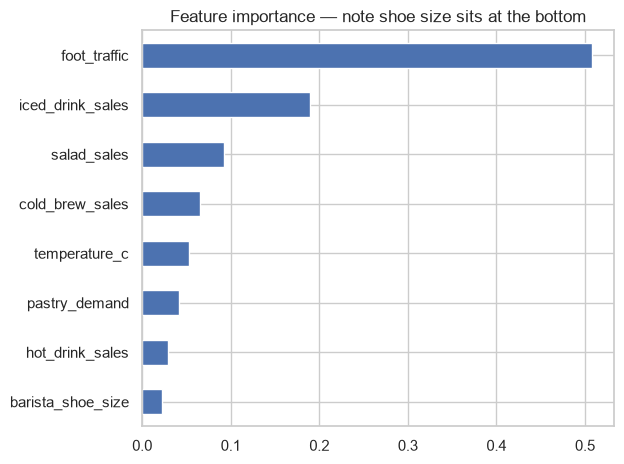

In [5]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(cafe[feats], cafe['daily_revenue'],
                                      test_size=.25, random_state=0)
rf = RandomForestRegressor(n_estimators=200, random_state=0).fit(Xtr, ytr)
print('test R² =', round(rf.score(Xte, yte), 3))
imp = pd.Series(rf.feature_importances_, index=feats).sort_values()
imp.plot.barh(); plt.title('Feature importance — note shoe size sits at the bottom')
plt.tight_layout(); plt.show()

**Reading the result:** the test $R^2 \approx 0.61$, so the model explains about 61 % of the variation in revenue on days it never saw during training.
The importance chart broadly agrees with the correlation ranking: the strong predictors rise to the top and
`barista_shoe_size` sits at the bottom, confirming it is noise. Note that importance can be *split* between
collinear features (temperature and iced drinks), so neither may look as important as it really is.

### Key takeaways
- Regression turns a correlation into a **prediction**: $\hat{y} = \beta_0 + \beta_1 x$, with $\beta_1 = r\,s_y/s_x$.
- Correlation guides **feature selection**: keep strong predictors, remove redundant and useless ones.
- Evaluate models on **unseen test data**, and remember: good prediction ≠ causation.